In [ ]:
!pip install nnv

Importamos libreria

* TensorFlow: es una biblioteca de codigo abierto para aprendizaje automatico a traves de un rango de tareas desarrollado por Google
* Keras: es una biblioteca de redes neuronales de codigo abierto escrita en python






In [ ]:
import tensorflow as tf
from tensorflow import keras

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


Cargamos dataset fashion_mnist

In [ ]:
fashion_mnist = keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


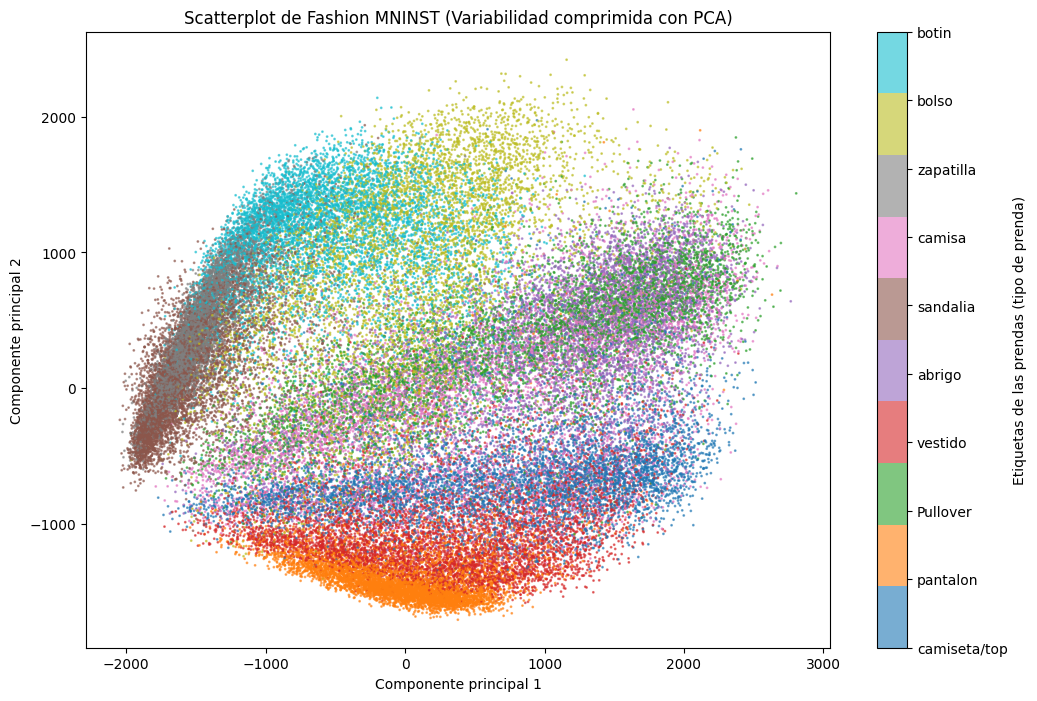

In [ ]:
#importar la herramienta PCA de sickit-learn
from sklearn.decomposition import PCA

#preparar los datos (aplanamiento)
#PCA necesita una tabla plana (filas=imagenes columna=pixeles)
#pero train_imagenes es un "cubo" de 60000, 28, 28
#las aplanamos para que queden como 60000 filas de 784 pixeles
#(esto hace matematicamente lo mismo que la capa kera.layers.Fltte del tutorial)

train_images_planas = train_images.reshape(train_images.shape[0], 28*28)

#configurar e instanciar PCA a 2 componentes
#le pedimos que comprima los 784 variables a solo 2 componentes (eje x eje y)
class_names = ['camiseta/top', 'pantalon', 'Pullover', 'vestido', 'abrigo',
               'sandalia', 'camisa', 'zapatilla', 'bolso', 'botin']
pca = PCA(n_components=2)

#aplicar la compresion a los datos
#nota: puede tardar unos segundos porque esta procesando la matematica de 60000 fotos

datos_2d = pca.fit_transform(train_images_planas)

#generar el grafico de scatter plot (grafico de dispercion)

plt.figure(figsize=(12,8)) #tamaño de la foto

#dibujamos los puntos
#explicacion de los parametros
# x e y= las dos nuevas columnas comprimidas (datos_2d)
#c=train_labels : le asigna un color distinto a cada etiqueta
#cmap="tab10": usa una paleta predeterminada de 10 colores
#c=1 alpha=0.5: hace los puntos chiquitos y transparentes para que se distingan

scatter= plt.scatter(datos_2d[:,0], datos_2d[:,1], c=train_labels, cmap="tab10", s=1 , alpha=0.6)

#agregamos detalles a los graficos
cbar = plt.colorbar(scatter)
cbar.set_ticks(range(10))
cbar.set_ticklabels(class_names)
cbar.set_label("Etiquetas de las prendas (tipo de prenda)")

plt.title("Scatterplot de Fashion MNINST (Variabilidad comprimida con PCA)")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

#mostrar el grafico

plt.show()

### Paso 1: Preparación y Escalado de los Datos

Aplanamos las imágenes de prueba al igual que hicimos con las de entrenamiento, y normalizamos dividiendo por `255.0` para que todos los píxeles estén en el rango `[0, 1]`.

In [ ]:
# Aplanamos las imágenes de prueba
test_images_planas = test_images.reshape(test_images.shape[0], 28*28)

# Normalizamos dividiendo por 255.0 (escalado al rango 0-1)
X_train = train_images_planas / 255.0
X_test = test_images_planas / 255.0

y_train = train_labels
y_test = test_labels

print("Forma de X_train (normalizado):", X_train.shape)
print("Forma de X_test (normalizado):", X_test.shape)

Forma de X_train (normalizado): (60000, 784)
Forma de X_test (normalizado): (10000, 784)


Paso 2 Definicion de la Arquitectura de la Red


Para mejorar la legibilidad , el rendimiento y la depuracion separamos los bloques de codigo para cada modelo

Entrenamiento de Random Forest

* Dado que 784 caracteristicas con 60000 muestras puede ser lento, configuramos n_estimators=25 como primera prueba y despues aumentaremos el numero de arboles y analizaremos como generaliza el modelo , max_depth=20 (para evitar overfitting y acelerar)
* Para usar todos los procesadores de colab definimos n_jobs=-1



In [ ]:
from sklearn.ensemble import RandomForestClassifier
import time
from sklearn.metrics import accuracy_score
print("----Entrenando Random Forest----")
start_rf = time.time()  #instanciamos el modelo con paralelizacion (n_jobs=-1)
rf_model = RandomForestClassifier(
    n_estimators=25,
    max_depth=20,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Entrenamiento
rf_model.fit(X_train, y_train)
time_rf = time.time() - start_rf
print("Tiempo de entrenamiento Random Forest:", time_rf, "segundos")

# Precicciones
y_pred_rf = rf_model.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Exactitud de Random Forest:", accuracy_rf)




----Entrenando Random Forest----
Tiempo de entrenamiento Random Forest: 30.95633053779602 segundos
Exactitud de Random Forest: 0.868


Random Forest
* Graficos
* Metricas
para ejecutar codigo que muestre graficos y metricas importamos librerias
* sklearn.metrics: Proporciona las funciones estadisticas (accuracy_score, classidication_report, confusion_matrix)
* numpy: Realiza la manipulacion matematica de los vectores y matrices de datos  
* matplotlib.pyplot y seaborn: Cosntituyen la capa de visualizacion de datos, plt gestiona la estructura general de la figura y sns genera la representacion grafica del mapa de calor (heatmap) para la matriz de confusion





------EVALUACION DE SESGO Y VARIANZA (RANDOM FOREST)----
Accuracy en Entrenamiento (Train): 0.991
Accuracy en Prueba (test):          0.868
Brecha (Overfitting):   3.08
-----REPORTE DE CLSIFICACION POR PRENDA-------
              precision    recall  f1-score   support

camiseta/top       0.80      0.85      0.82      1000
    pantalon       0.99      0.96      0.98      1000
    Pullover       0.75      0.79      0.77      1000
     vestido       0.87      0.90      0.88      1000
      abrigo       0.75      0.80      0.78      1000
    sandalia       0.97      0.96      0.96      1000
      camisa       0.70      0.56      0.62      1000
   zapatilla       0.92      0.94      0.93      1000
       bolso       0.96      0.97      0.97      1000
       botin       0.95      0.95      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



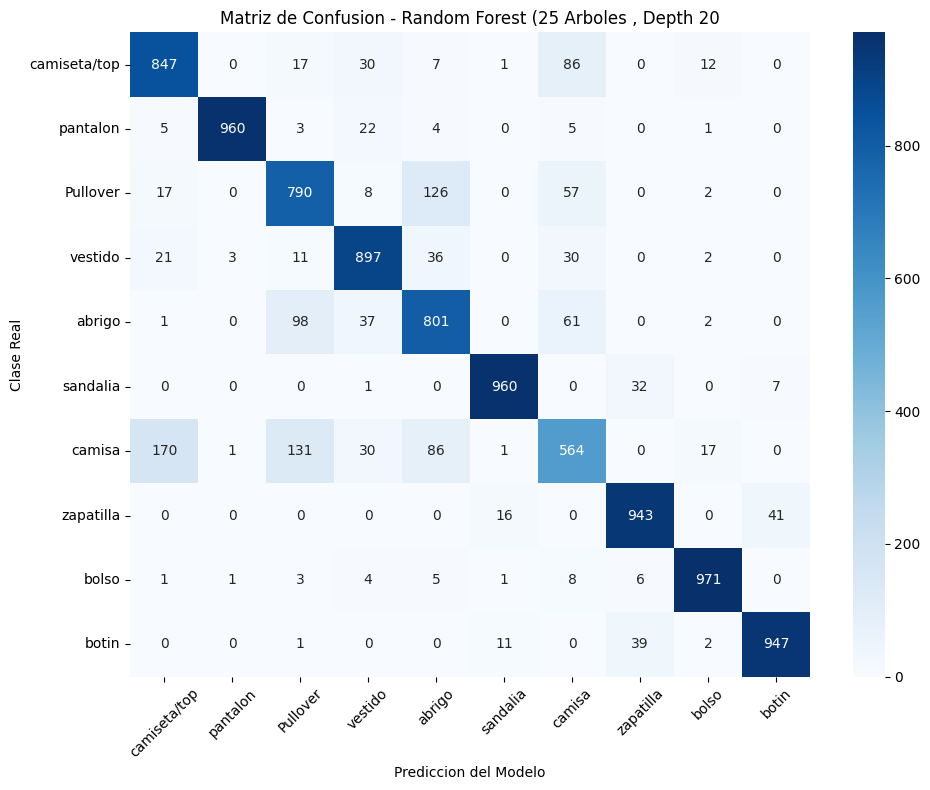

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

#1 Precision den Entrenamiento vs Test para detectar overfitting
acc_train_rf = rf_model.score(X_train, y_train)
acc_test_rf = accuracy_rf   #ya la tengo calculada

print("------EVALUACION DE SESGO Y VARIANZA (RANDOM FOREST)----")
print(f"Accuracy en Entrenamiento (Train): {acc_train_rf:.3f}")
print(f"Accuracy en Prueba (test):          {acc_test_rf:.3f}")
print(f"Brecha (Overfitting):   {(acc_train_rf - acc_test_rf)*25:.2f}")

#2 Repoere de Metricas por Clase (Precision,Recall, F1 score
print("-----REPORTE DE CLSIFICACION POR PRENDA-------")
print(classification_report(y_test, y_pred_rf, target_names=class_names))

# 3 Matriz de Confusion
plt.figure(figsize=(10, 8))
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Matriz de Confusion - Random Forest (25 Arboles , Depth 20")
plt.xlabel("Prediccion del Modelo")
plt.ylabel("Clase Real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Entrenamiento de Red Neuranal Perceptron Multicapa (MLP)

* Permite aprender representaciones de caracteristicas no lineales automaticamente mediante capas y funciones de activacion como ReLU
* Aprovecha la aceleracion por GPU/TPU y algoritmos de optimizacion eficientes ( Adam o SGD )




In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

#1 definicion del modelo (Perceptron Multicapa / Dense NN)
model = keras.Sequential([
    layers.Input(shape=(784,)),            #entrada: 784 pixeles aplanados
    layers.Dense(128, activation='relu'),  #capa oculta 1
    layers.Dense(64, activation='relu'),   #capa oculta 2
    layers.Dropout(0.2),                   #Regularizacion para evitar overfitting
    layers.Dense(10, activation='softmax') #salida: 10 clases de fashion.mnist
])

#2. compilacon con metricas de evaluacion
model.compile(
               optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Paso 3 Entrenamiento con Early Stopping

In [ ]:
from sklearn.model_selection import train_test_split

# Separar una parte de los datos de entrenamiento para validar el modelo
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Detener el entrenamiento si la pérdida de validación no mejora
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Entrenamiento: X_test e y_test quedan reservados para la evaluación final
history = model.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8700 - loss: 0.3553 - val_accuracy: 0.8699 - val_loss: 0.3576
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8798 - loss: 0.3318 - val_accuracy: 0.8681 - val_loss: 0.3583
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8832 - loss: 0.3177 - val_accuracy: 0.8706 - val_loss: 0.3534
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8889 - loss: 0.3010 - val_accuracy: 0.8776 - val_loss: 0.3387
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8920 - loss: 0.2898 - val_accuracy: 0.8662 - val_loss: 0.3696


Paso 3 Evaluacion y Curvas de Aprendizaje

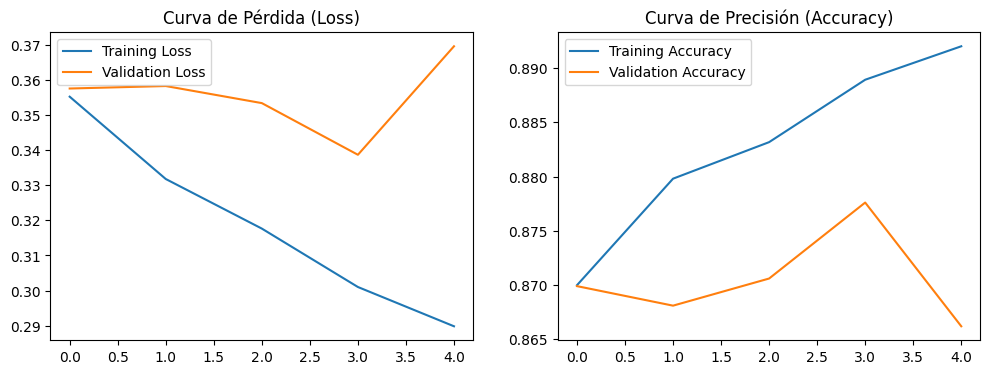

Precisión en el conjunto de prueba (test_accuracy): {test_accuracy:.4f}


In [ ]:
# 1. Graficos de Perdida y Precision (Accuracy)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Curva de Pérdida (Loss)')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Curva de Precisión (Accuracy)')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

# 2. Evaluación final en el conjunto de prueba (no usado durante el entrenamiento)
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Precisión en el conjunto de prueba (test_accuracy): {test_accuracy:.4f}")
print(f"Pérdida en el conjunto de prueba (test_loss): {test_loss:.4f}")


Paso 4 Matriz se Confusion para diagnostico tecnico


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


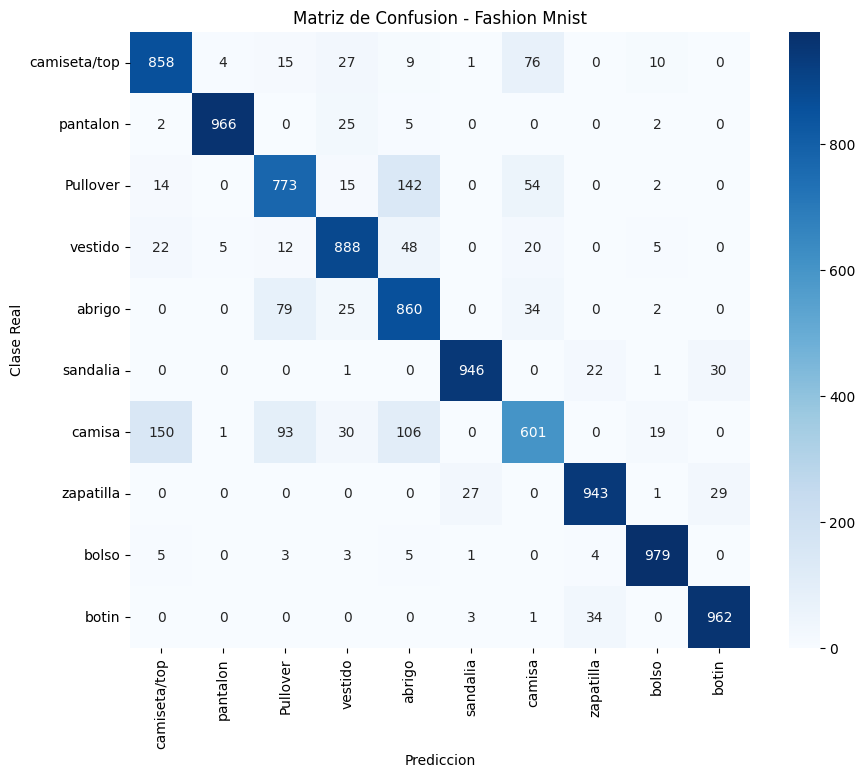

              precision    recall  f1-score   support

camiseta/top       0.82      0.86      0.84      1000
    pantalon       0.99      0.97      0.98      1000
    Pullover       0.79      0.77      0.78      1000
     vestido       0.88      0.89      0.88      1000
      abrigo       0.73      0.86      0.79      1000
    sandalia       0.97      0.95      0.96      1000
      camisa       0.76      0.60      0.67      1000
   zapatilla       0.94      0.94      0.94      1000
       bolso       0.96      0.98      0.97      1000
       botin       0.94      0.96      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_pred = np.argmax(model.predict(X_test), axis=-1)

# Matriz de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True,fmt="d" , cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediccion")
plt.ylabel("Clase Real")
plt.title("Matriz de Confusion - Fashion Mnist")
plt.show()

# Reporte detallado (Precision, Recall F1-Score)

print(classification_report(y_test, y_pred, target_names=class_names))
